# Laboratório — Redes Neurais Recorrentes (RNN) — Introdução

# Setup

In [1]:
# Importar as bibliotecas utilizadas no notebook

import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Definir sementes para tornar os experimentos mais reproduzíveis

np.random.seed(42)
tf.random.set_seed(42)


# 1. Dataset: textos como sequências

In [2]:
# Criar um pequeno dataset didático de avaliações de produtos.
# Cada texto é uma instância e a classe indica:
# 1 = avaliação positiva
# 0 = avaliação negativa

positivos = [
    "produto muito bom",
    "gostei muito do produto",
    "qualidade excelente e acabamento bom",
    "produto funciona muito bem",
    "compra valeu a pena",
    "produto chegou perfeito",
    "material de boa qualidade",
    "produto superou minhas expectativas",
    "estou satisfeito com a compra",
    "recomendo este produto",
    "produto bonito e confortável",
    "ótimo produto para o preço",
    "funcionou perfeitamente",
    "produto fácil de usar",
    "boa qualidade e bom acabamento",
    "não tive problemas com o produto",
    "produto chegou rápido e funcionando",
    "gostei do acabamento",
    "vale muito a pena",
    "produto excelente",
    "muito satisfeito com o produto",
    "compra muito boa",
    "produto atende bem",
    "recomendo a compra"
]

negativos = [
    "produto muito ruim",
    "não gostei do produto",
    "qualidade péssima e acabamento ruim",
    "produto não funciona bem",
    "compra não valeu a pena",
    "produto chegou quebrado",
    "material de baixa qualidade",
    "produto ficou abaixo das expectativas",
    "estou insatisfeito com a compra",
    "não recomendo este produto",
    "produto desconfortável e frágil",
    "péssimo produto para o preço",
    "não funcionou corretamente",
    "produto difícil de usar",
    "baixa qualidade e acabamento ruim",
    "tive muitos problemas com o produto",
    "produto chegou com defeito",
    "não gostei do acabamento",
    "não vale a pena",
    "produto péssimo",
    "muito insatisfeito com o produto",
    "compra muito ruim",
    "produto não atende bem",
    "não recomendo a compra"
]

textos = np.array(positivos + negativos)
rotulos = np.array([1] * len(positivos) + [0] * len(negativos))

# Embaralhar antes de separar treinamento e teste

indices = np.random.permutation(len(textos))
textos = textos[indices]
rotulos = rotulos[indices]

corte = int(0.80 * len(textos))

textos_treino = textos[:corte]
y_train = rotulos[:corte]

textos_teste = textos[corte:]
y_test = rotulos[corte:]

print(f"Total de instâncias: {len(textos)}")
print(f"Treinamento:         {len(textos_treino)}")
print(f"Teste:               {len(textos_teste)}")

print("\nExemplos:")
for texto, classe in zip(textos_treino[:5], y_train[:5]):
    print(f"{classe} -> {texto}")


Total de instâncias: 48
Treinamento:         38
Teste:               10

Exemplos:
0 -> produto não funciona bem
0 -> produto chegou com defeito
0 -> qualidade péssima e acabamento ruim
0 -> produto péssimo
0 -> produto muito ruim


## Perguntas

1. O que representa cada instância deste dataset?  
2. Por que a ordem dos tokens pode ser relevante para classificar esses textos?


# 2. Tokenização e definição dos timesteps

In [3]:
# Definir quantos tokens de cada documento serão apresentados à RNN.
# T = quantidade de timesteps.

T = 8

vectorizador = layers.TextVectorization(
    max_tokens=200,
    output_mode="int",
    output_sequence_length=T
)

# O vocabulário é aprendido apenas com os textos de treinamento.

vectorizador.adapt(textos_treino)

X_train = vectorizador(textos_treino).numpy()
X_test = vectorizador(textos_teste).numpy()

vocabulario = vectorizador.get_vocabulary()

print(f"Tamanho do vocabulário: {len(vocabulario)}")
print(f"Shape de X_train:       {X_train.shape}")
print(f"Shape de X_test:        {X_test.shape}")

# Observar dois exemplos: um curto e um mais longo que T.

exemplos = np.array([
    "produto excelente",
    "produto muito bom e fácil de usar e chegou rápido funcionando perfeitamente"
])

ids_exemplos = vectorizador(exemplos).numpy()

for texto, ids in zip(exemplos, ids_exemplos):
    print("\nTexto:", texto)
    print("Tokens:", texto.lower().split())
    print("IDs entregues ao modelo:", ids)


Tamanho do vocabulário: 57
Shape de X_train:       (38, 8)
Shape de X_test:        (10, 8)

Texto: produto excelente
Tokens: ['produto', 'excelente']
IDs entregues ao modelo: [ 2 29  0  0  0  0  0  0]

Texto: produto muito bom e fácil de usar e chegou rápido funcionando perfeitamente
Tokens: ['produto', 'muito', 'bom', 'e', 'fácil', 'de', 'usar', 'e', 'chegou', 'rápido', 'funcionando', 'perfeitamente']
IDs entregues ao modelo: [ 2  4 32 10 44 12 19 10]


## Perguntas

3. O que o valor `T = 8` determina na preparação das instâncias?  
4. Como padding e truncamento aparecem nos dois exemplos impressos?


# 3. Embedding: um vetor para cada token

In [4]:
# Cada token será representado por um vetor denso com F atributos.

F = 8

embedding_demo = layers.Embedding(
    input_dim=len(vocabulario),
    output_dim=F,
    mask_zero=True
)

amostra_ids = X_train[:2]
amostra_embeddings = embedding_demo(amostra_ids)

print(f"Entrada em IDs:       {amostra_ids.shape}")
print(f"Saída do Embedding:   {amostra_embeddings.shape}")

print("\nPrimeira instância em IDs:")
print(amostra_ids[0])

print("\nVetor de embedding do primeiro token:")
print(np.round(amostra_embeddings[0, 0].numpy(), 3))


Entrada em IDs:       (2, 8)
Saída do Embedding:   (2, 8, 8)

Primeira instância em IDs:
[ 2  3 28 18  0  0  0  0]

Vetor de embedding do primeiro token:
[-0.03  -0.033  0.001  0.041  0.004  0.036 -0.05   0.03 ]


## Perguntas

5. Como interpretar o shape `(2, 8, 8)` produzido pelo Embedding?  
6. Por que todos os tokens precisam ser representados por vetores com a mesma dimensão `F`?


# 4. Processamento recorrente ao longo da sequência

In [5]:
# Usar uma SimpleRNN apenas para observar os estados produzidos
# ao longo dos timesteps.

H = 6

rnn_demo = layers.SimpleRNN(
    units=H,
    return_sequences=True
)

estados = rnn_demo(amostra_embeddings)

print(f"Entrada da RNN: {amostra_embeddings.shape}")
print(f"Saída da RNN:   {estados.shape}")

print("\nEstados dos três primeiros timesteps da primeira instância:")
print(np.round(estados[0, :3].numpy(), 3))


Entrada da RNN: (2, 8, 8)
Saída da RNN:   (2, 8, 6)

Estados dos três primeiros timesteps da primeira instância:
[[ 0.041 -0.031 -0.011  0.013 -0.011 -0.029]
 [ 0.025 -0.002  0.009  0.025  0.003  0.028]
 [-0.004  0.023 -0.023  0.022 -0.063 -0.039]]


## Perguntas

7. No shape `(2, 8, 6)`, o que representam as dimensões `8` e `6`?  
8. O que significa dizer que a mesma camada RNN é reutilizada ao longo dos 8 timesteps?


# 5. Modelo completo e parâmetros da camada recorrente

In [6]:
# Construir um classificador:
# sequência de IDs -> Embedding -> SimpleRNN -> Dense

entrada = keras.Input(shape=(T,), dtype="int64", name="entrada")

embedding = layers.Embedding(
    input_dim=len(vocabulario),
    output_dim=F,
    mask_zero=True,
    name="embedding"
)

vetores = embedding(entrada)

rnn = layers.SimpleRNN(
    units=H,
    return_sequences=True,
    return_state=True,
    name="rnn"
)

sequencia_estados, estado_final = rnn(vetores)

saida = layers.Dense(
    1,
    activation="sigmoid",
    name="saida"
)(estado_final)

model = keras.Model(
    inputs=entrada,
    outputs=saida
)

# Modelo auxiliar para observar os estados internos da mesma RNN.

modelo_estados = keras.Model(
    inputs=entrada,
    outputs=[sequencia_estados, estado_final]
)

model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ entrada             │ (None, 8)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 8, 8)      │        456 │ entrada[0][0]     │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 8)         │          0 │ entrada[0][0]     │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rnn (SimpleRNN)     │ [(None, 8, 6),    │         90 │ embedding[0][0],  │
│                     │ (None, 6)]        │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ saida (Dense)       │ (None, 1)         │          7 │ rnn[0][1]         │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 553 (2.16 KB)

 Trainable params: 553 (2.16 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
# Inspecionar os parâmetros treináveis da camada RNN.
#
# No Keras:
# kernel            -> conexões da entrada atual para os H neurônios
# recurrent_kernel  -> conexões do estado anterior para os H neurônios
# bias              -> um bias por neurônio

kernel, recurrent_kernel, bias = model.get_layer("rnn").get_weights()

print(f"kernel:            {kernel.shape}")
print(f"recurrent_kernel:  {recurrent_kernel.shape}")
print(f"bias:              {bias.shape}")

parametros_rnn = (F * H) + (H * H) + H

print(f"\nCálculo manual: ({F} × {H}) + ({H} × {H}) + {H}")
print(f"Parâmetros da RNN: {parametros_rnn}")
print(f"Keras count_params(): {model.get_layer('rnn').count_params()}")

# Observar todos os estados e o estado final de uma instância.

todos_estados, ultimo_estado = modelo_estados(X_train[:1])

print(f"\nTodos os estados: {todos_estados.shape}")
print(f"Estado final:      {ultimo_estado.shape}")


kernel:            (8, 6)
recurrent_kernel:  (6, 6)
bias:              (6,)

Cálculo manual: (8 × 6) + (6 × 6) + 6
Parâmetros da RNN: 90
Keras count_params(): 90

Todos os estados: (1, 8, 6)
Estado final:      (1, 6)


## Perguntas

9. Como interpretar os shapes de `kernel`, `recurrent_kernel` e `bias` impressos pelo Keras?  
10. Refaça manualmente o cálculo da quantidade de parâmetros treináveis da `SimpleRNN`.  
11. Qual é o papel do `estado_final` na classificação realizada por este modelo?


# 6. Treinamento

Treinamento concluído.
Accuracy final de treinamento: 0.9286
Accuracy final de validação:   0.6000


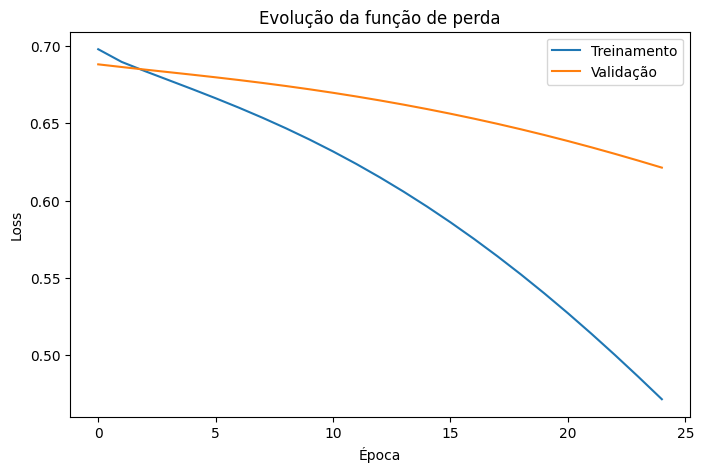

In [8]:
# Configurar e treinar o modelo.

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

historico = model.fit(
    X_train,
    y_train,
    epochs=25,
    batch_size=8,
    validation_split=0.25,
    verbose=0
)

print("Treinamento concluído.")
print(f"Accuracy final de treinamento: {historico.history['accuracy'][-1]:.4f}")
print(f"Accuracy final de validação:   {historico.history['val_accuracy'][-1]:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(historico.history["loss"], label="Treinamento")
plt.plot(historico.history["val_loss"], label="Validação")
plt.xlabel("Época")
plt.ylabel("Loss")
plt.title("Evolução da função de perda")
plt.legend()
plt.show()


## Perguntas

12. Quais hiperparâmetros de treinamento foram definidos nesta etapa?  
13. Quais parâmetros do modelo são efetivamente alterados pelo otimizador durante o treinamento?  
14. O gráfico de loss sugere aprendizado adequado ou sinais de overfitting neste experimento?


# 7. Avaliação e novas previsões

In [9]:
# Avaliar no conjunto de teste.

loss_teste, acuracia_teste = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print(f"Loss no teste:     {loss_teste:.4f}")
print(f"Acurácia no teste: {acuracia_teste:.4f}")


Loss no teste:     0.6677
Acurácia no teste: 0.5000


In [10]:
# Fazer previsões em novos textos.

novos_textos = np.array([
    "produto muito bom",
    "produto não é bom",
    "gostei muito da compra",
    "não gostei da compra"
])

novos_ids = vectorizador(novos_textos)
probabilidades = model.predict(novos_ids, verbose=0).ravel()

for texto, prob in zip(novos_textos, probabilidades):
    classe = "positiva" if prob >= 0.5 else "negativa"
    print(f"{prob:.3f} -> {classe:8s} | {texto}")


0.497 -> negativa | produto muito bom
0.257 -> negativa | produto não é bom
0.507 -> positiva | gostei muito da compra
0.281 -> negativa | não gostei da compra


## Perguntas

15. O que a acurácia de teste informa sobre o desempenho do modelo em dados não utilizados diretamente no treinamento?  
16. Compare as previsões das frases com e sem negação. O que esse resultado ilustra sobre o processamento sequencial da RNN?
